# Задание 4. Методы классификации (повышение эффективности их работы)

Датасет `fraud.csv`: 1879 сканирований на кассах самообслуживания. Нужно отличить мошенничество (`fraud = 1`) от честной покупки.

- trustLevel: уровень доверия к покупателю (1 – низкий, 6 – высокий)
- totalScanTimeInSeconds: время от первого до последнего сканирования, с
- grandTotal: сумма чека
- lineItemVoids: число отменённых позиций
- scansWithoutRegistration: попытки сканирования без результата
- quantityModifications: изменения количества товара
- scannedLineItemsPerSecond: позиций в секунду
- valuePerSecond: сумма в секунду
- lineItemVoidsPerPosition: доля отменённых позиций
- fraud: целевая переменная

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier, AdaBoostClassifier, StackingClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, f1_score, log_loss, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

RS = 42
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("fraud.csv", sep="|")
print(df.shape, "пропусков:", df.isna().sum().sum())
df.describe().T.round(3)

(1879, 10) пропусков: 0


,count,mean,std,min,25%,50%,75%,max
trustLevel,1879.0,3.402,1.709,1.000,2.000,3.000,5.000,6.000
totalScanTimeInSeconds,1879.0,932.153,530.145,2.000,474.500,932.000,1397.000,1831.000
grandTotal,1879.0,50.864,28.940,0.010,25.965,51.210,77.285,99.960
lineItemVoids,1879.0,5.470,3.451,0.000,2.000,5.000,8.000,11.000
scansWithoutRegistration,1879.0,4.904,3.140,0.000,2.000,5.000,8.000,10.000
quantityModifications,1879.0,2.525,1.695,0.000,1.000,3.000,4.000,5.000
scannedLineItemsPerSecond,1879.0,0.058,0.279,0.001,0.008,0.016,0.033,6.667
valuePerSecond,1879.0,0.202,1.242,0.000,0.028,0.054,0.107,37.870
lineItemVoidsPerPosition,1879.0,0.745,1.327,0.000,0.160,0.350,0.667,11.000
fraud,1879.0,0.055,0.229,0.000,0.000,0.000,0.000,1.000


In [3]:
print(df["fraud"].value_counts())
print("доля мошенничества:", round(df["fraud"].mean(), 3))

fraud
0    1775
1     104
Name: count, dtype: int64
доля мошенничества: 0.055


Выборка несбалансированная: мошеннических чеков 5.5%. Модель, которая всегда отвечает «честно», получит Accuracy 0.945 и не найдёт ни одного мошенника. Поэтому главными метриками считаю F-меру и ROC-AUC, а Accuracy смотрю только вместе с ними.

In [4]:
X = df.drop(columns="fraud")
y = df["fraud"].values

def scores(y_true, pred, proba=None):
    r = {"Accuracy": accuracy_score(y_true, pred), "F1": f1_score(y_true, pred)}
    if proba is not None:
        r["LogLoss"] = log_loss(y_true, proba)
        r["ROC-AUC"] = roc_auc_score(y_true, proba)
    else:
        r["LogLoss"] = np.nan
        r["ROC-AUC"] = np.nan
    return r

def base_models():
    return {
        "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance")),
        "SVM": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(kernel="rbf", C=10), ensemble=False)),
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=5000)),
    }

## 1. Результаты прошлой работы: отложенная выборка 70/30

Повторяю схему третьего задания, чтобы было с чем сравнивать: одно стратифицированное разбиение, 30% в тест.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RS)

holdout = {}
holdout_cm = {}
for name, m in base_models().items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    pred = m.predict(X_te)
    holdout[name] = scores(y_te, pred, p)
    holdout_cm[name] = confusion_matrix(y_te, pred)

res_holdout = pd.DataFrame(holdout).T.round(3)
res_holdout

,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.949,0.121,0.297,0.897
SVM,0.950,0.533,0.107,0.963
LogReg,0.973,0.746,0.066,0.990


## 1.2. k-fold кросс-валидация (k = 5)

Для каждой модели получаю предсказания вне фолда (out-of-fold): каждый объект предсказан моделью, которая его не видела. По ним считаю метрики на всей выборке, а разброс по фолдам показываю отдельно.

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def cv_eval(model, X, y, resampler=None, has_proba=True):
    X = np.asarray(X, dtype=float)
    oof_pred = np.zeros(len(y), dtype=int)
    oof_proba = np.zeros(len(y))
    fold_f1, fold_auc = [], []
    for tr, te in skf.split(X, y):
        X_fit, y_fit = X[tr], y[tr]
        if resampler is not None:
            X_fit, y_fit = resampler(X_fit, y_fit)
        m = clone(model).fit(X_fit, y_fit)
        oof_pred[te] = m.predict(X[te])
        fold_f1.append(f1_score(y[te], oof_pred[te]))
        if has_proba:
            oof_proba[te] = m.predict_proba(X[te])[:, 1]
            fold_auc.append(roc_auc_score(y[te], oof_proba[te]))
    r = scores(y, oof_pred, oof_proba if has_proba else None)
    r["F1 std"] = np.std(fold_f1)
    return r, oof_pred, (oof_proba if has_proba else None)

results = {}      # сводная таблица по всем этапам
oof = {}          # предсказания вне фолда для ROC и матриц ошибок

for name, m in base_models().items():
    r, pred, proba = cv_eval(m, X, y)
    results[f"{name} (CV)"] = r
    oof[f"{name} (CV)"] = (pred, proba)

res_cv = pd.DataFrame(results).T.round(3)
res_cv

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
SVM (CV),0.955,0.491,0.098,0.969,0.062
LogReg (CV),0.978,0.777,0.061,0.990,0.035


In [7]:
cmp = pd.concat({"hold-out 70/30": res_holdout,
                 "5-fold CV": res_cv.drop(columns="F1 std").rename(index=lambda s: s.replace(" (CV)", ""))},
                axis=1)
cmp

hold-out 70/30                        5-fold CV                       
             Accuracy     F1 LogLoss ROC-AUC  Accuracy     F1 LogLoss ROC-AUC
kNN             0.949  0.121   0.297   0.897     0.940  0.082   0.510   0.828
SVM             0.950  0.533   0.107   0.963     0.955  0.491   0.098   0.969
LogReg          0.973  0.746   0.066   0.990     0.978  0.777   0.061   0.990

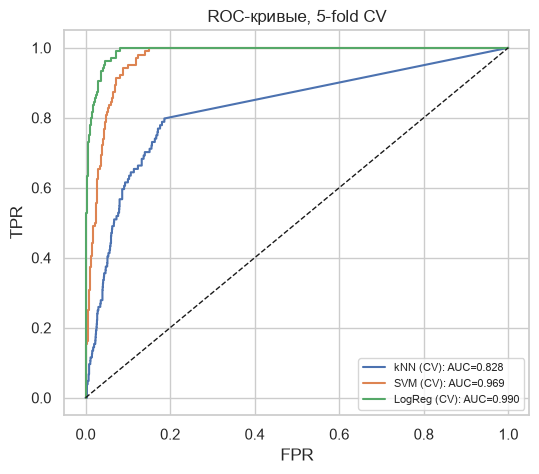

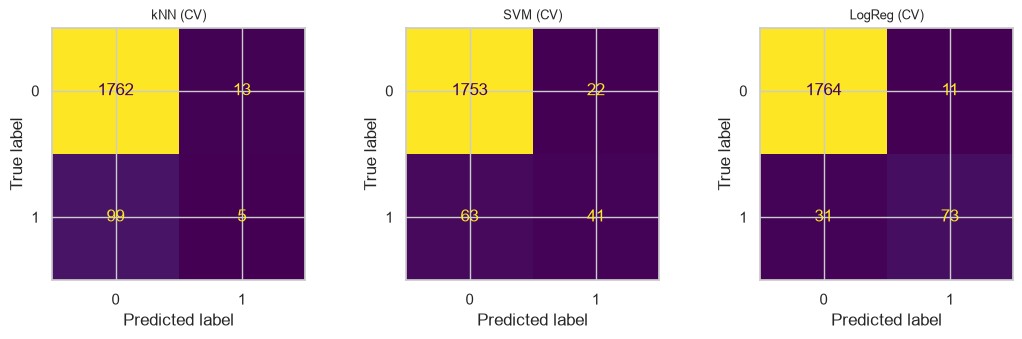

In [8]:
def plot_roc(keys, title):
    plt.figure(figsize=(6, 5))
    for k in keys:
        proba = oof[k][1]
        if proba is None:
            continue
        fpr, tpr, _ = roc_curve(y, proba)
        plt.plot(fpr, tpr, label=f"{k}: AUC={roc_auc_score(y, proba):.3f}")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(title); plt.legend(fontsize=8)
    plt.show()

def plot_cm(keys):
    fig, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 3.4))
    for ax, k in zip(np.atleast_1d(axes), keys):
        ConfusionMatrixDisplay(confusion_matrix(y, oof[k][0])).plot(ax=ax, colorbar=False)
        ax.set_title(k, fontsize=9)
    plt.tight_layout(); plt.show()

plot_roc(list(oof), "ROC-кривые, 5-fold CV")
plot_cm(list(oof))

#### Выводы по 1.2

В тест отложенной выборки попал 31 мошеннический чек, и одна ошибка там сдвигает F1 на 2–3 сотых. Кросс-валидация проверяет модели на всех 104 мошенничествах. Порядок моделей не изменился, но оценки сдвинулись: у логистической регрессии F1 вырос с 0.746 до 0.777, у SVM упал с 0.533 до 0.491, ROC-AUC у kNN упал с 0.897 до 0.828. Разброс между фолдами показывает `F1 std`: от 0.035 у LogReg до 0.092 у kNN.

Логистическая регрессия сильнее остальных: F1 0.777, ROC-AUC 0.990, LogLoss 0.061. kNN почти бесполезен: из 104 мошенников он нашёл 5. Мошенничество встречается только у клиентов с trustLevel 1 и 2, но честных среди них 575, поэтому среди ближайших соседей мошенника почти всегда больше честных чеков.

## 1.3. Композиция моделей: Hard Voting и Soft Voting

Hard voting берёт класс, за который проголосовало большинство из трёх моделей. Soft voting усредняет вероятности. У hard voting вероятностей нет, поэтому LogLoss и ROC-AUC для него не считаются.

In [9]:
estimators = list(base_models().items())

hard = VotingClassifier(estimators, voting="hard")
soft = VotingClassifier(estimators, voting="soft")

r, pred, proba = cv_eval(hard, X, y, has_proba=False)
results["Hard Voting"] = r; oof["Hard Voting"] = (pred, None)
r, pred, proba = cv_eval(soft, X, y)
results["Soft Voting"] = r; oof["Soft Voting"] = (pred, proba)

pd.DataFrame(results).T.round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
SVM (CV),0.955,0.491,0.098,0.969,0.062
LogReg (CV),0.978,0.777,0.061,0.990,0.035
Hard Voting,0.961,0.519,NaN,NaN,0.064
Soft Voting,0.960,0.506,0.090,0.979,0.077


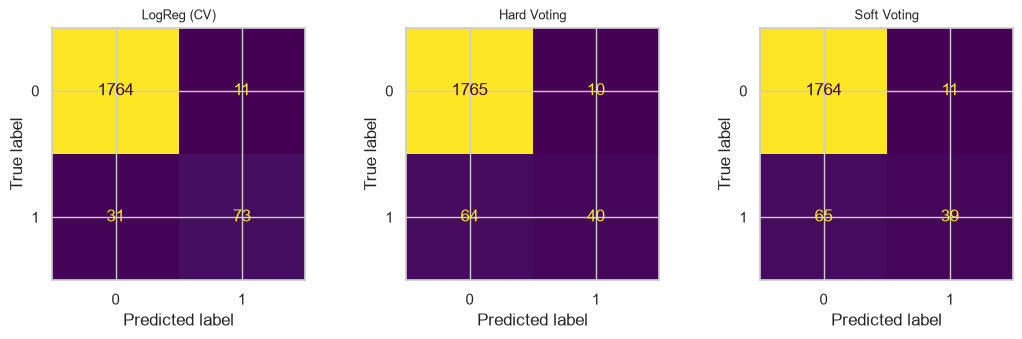

In [10]:
plot_cm(["LogReg (CV)", "Hard Voting", "Soft Voting"])

## 1.4. AdaBoost над деревом решений

Базовый алгоритм – неглубокое дерево CART (`max_depth=2`). Глубину и число деревьев подбираю на тех же фолдах по F1.

In [11]:
grid = []
for depth in [1, 2, 3]:
    for n in [100, 300]:
        ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth, random_state=RS),
                                 n_estimators=n, learning_rate=0.5, random_state=RS)
        r, _, _ = cv_eval(ada, X, y)
        grid.append({"max_depth": depth, "n_estimators": n, **r})
pd.DataFrame(grid).round(3).sort_values("F1", ascending=False)

,max_depth,n_estimators,Accuracy,F1,LogLoss,ROC-AUC,F1 std
5,3,300,0.980,0.814,0.311,0.994,0.042
3,2,300,0.981,0.814,0.351,0.994,0.019
2,2,100,0.979,0.796,0.303,0.993,0.054
4,3,100,0.978,0.790,0.282,0.993,0.034
1,1,300,0.974,0.735,0.392,0.990,0.042
0,1,100,0.965,0.582,0.358,0.984,0.110


In [12]:
best = max(grid, key=lambda g: g["F1"])
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=best["max_depth"], random_state=RS),
                         n_estimators=best["n_estimators"], learning_rate=0.5, random_state=RS)
r, pred, proba = cv_eval(ada, X, y)
results["AdaBoost"] = r; oof["AdaBoost"] = (pred, proba)

pd.DataFrame(results).T.round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
SVM (CV),0.955,0.491,0.098,0.969,0.062
LogReg (CV),0.978,0.777,0.061,0.990,0.035
Hard Voting,0.961,0.519,NaN,NaN,0.064
Soft Voting,0.960,0.506,0.090,0.979,0.077
AdaBoost,0.981,0.814,0.351,0.994,0.019


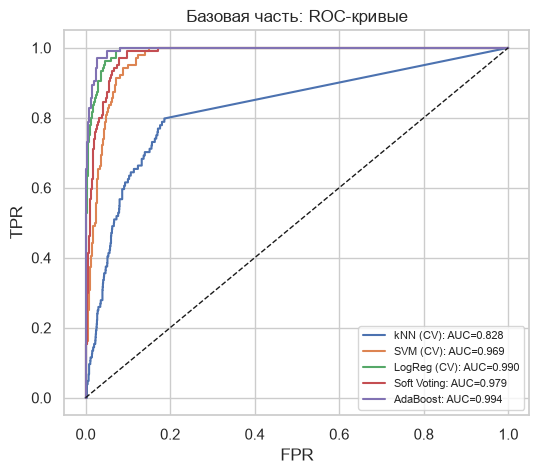

In [13]:
plot_roc(["kNN (CV)", "SVM (CV)", "LogReg (CV)", "Soft Voting", "AdaBoost"], "Базовая часть: ROC-кривые")

#### Выводы по базовой части

Голосование оказалось хуже лучшей одиночной модели: F1 0.519 у hard voting и 0.506 у soft voting против 0.777 у LogReg. Голосование помогает, когда модели примерно равны по силе и ошибаются на разных объектах. Здесь kNN и SVM ошибаются одинаково, оба пропускают мошенников, и при hard voting двое перебивают третьего. Hard voting нашёл 40 мошенников из 104, LogReg нашла 73.

Лучшим в базовой части стал AdaBoost на деревьях глубины 2 (300 деревьев): F1 0.814, ROC-AUC 0.994, найдено 79 мошенников при 11 ложных тревогах. Каждое следующее дерево учится с большим весом на объектах, где ошиблись предыдущие, а в этих данных такие объекты чаще всего мошенники. LogLoss у AdaBoost плохой (0.351 против 0.061 у LogReg): его вероятности сжаты к 0.5. Классы он разделяет хорошо, но вероятностям верить нельзя.

## 2.1. Upsampling: генерация искусственных объектов меньшего класса

Реализую идею SMOTE вручную: для каждого нового объекта беру случайного мошенника, одного из его 5 ближайших соседей того же класса и ставлю точку на отрезке между ними. Генерирую столько точек, чтобы классы сравнялись.

Важно: генерация идёт **только на обучающей части фолда**. Если сделать upsampling до разбиения, синтетические копии тестовых мошенников попадут в обучение и метрики будут завышены.

In [14]:
def smote_upsample(X, y, k=5, seed=RS):
    rng = np.random.default_rng(seed)
    X_min = X[y == 1]
    need = (y == 0).sum() - len(X_min)
    if need <= 0:
        return X, y
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
    _, idx = nn.kneighbors(X_min)
    base = rng.integers(0, len(X_min), need)
    neigh = idx[base, rng.integers(1, k + 1, need)]
    gap = rng.random((need, 1))
    X_new = X_min[base] + gap * (X_min[neigh] - X_min[base])
    return np.vstack([X, X_new]), np.concatenate([y, np.ones(need, dtype=int)])

# проверка на всей выборке, просто посмотреть на результат генерации
X_up, y_up = smote_upsample(X.values.astype(float), y)
print("до:", np.bincount(y), " после:", np.bincount(y_up))

до: [1775  104]  после: [1775 1775]


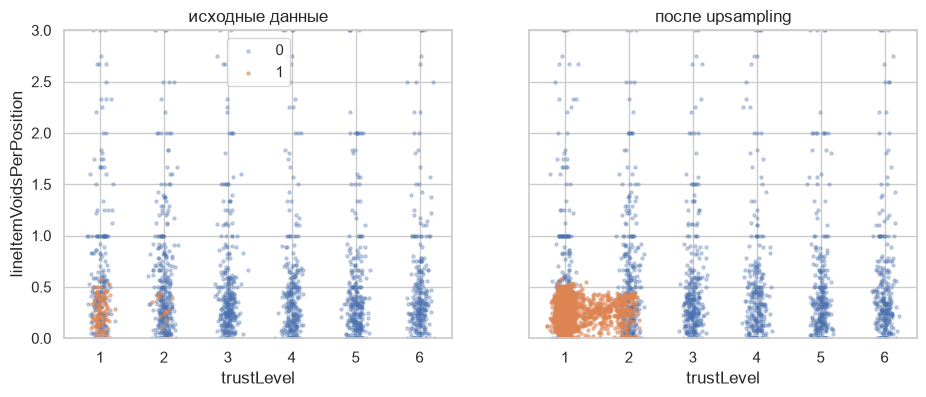

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
cols = ["trustLevel", "lineItemVoidsPerPosition"]
i0, i1 = [X.columns.get_loc(c) for c in cols]
for ax, (XX, yy, t) in zip(axes, [(X.values, y, "исходные данные"), (X_up, y_up, "после upsampling")]):
    ax.scatter(XX[yy == 0, i0] + np.random.normal(0, .08, (yy == 0).sum()), XX[yy == 0, i1], s=5, alpha=.3, label="0")
    ax.scatter(XX[yy == 1, i0] + np.random.normal(0, .08, (yy == 1).sum()), XX[yy == 1, i1], s=5, alpha=.5, label="1")
    ax.set_title(t); ax.set_xlabel(cols[0]); ax.set_ylim(0, 3)
axes[0].set_ylabel(cols[1]); axes[0].legend()
plt.show()

Синтетические мошенники ложатся туда же, где реальные: trustLevel от 1 до 2. При trustLevel 3 и выше мошенников в данных нет совсем, и интерполяция между соседями таких точек не создаёт.

## 2.2. kNN и SVM на сбалансированной обучающей выборке

In [16]:
for name in ["kNN", "SVM"]:
    r, pred, proba = cv_eval(base_models()[name], X, y, resampler=smote_upsample)
    results[f"{name} + upsampling"] = r
    oof[f"{name} + upsampling"] = (pred, proba)

pd.DataFrame(results).T.loc[["kNN (CV)", "kNN + upsampling", "SVM (CV)", "SVM + upsampling"]].round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
kNN + upsampling,0.830,0.356,2.167,0.876,0.031
SVM (CV),0.955,0.491,0.098,0.969,0.062
SVM + upsampling,0.965,0.680,0.129,0.980,0.084


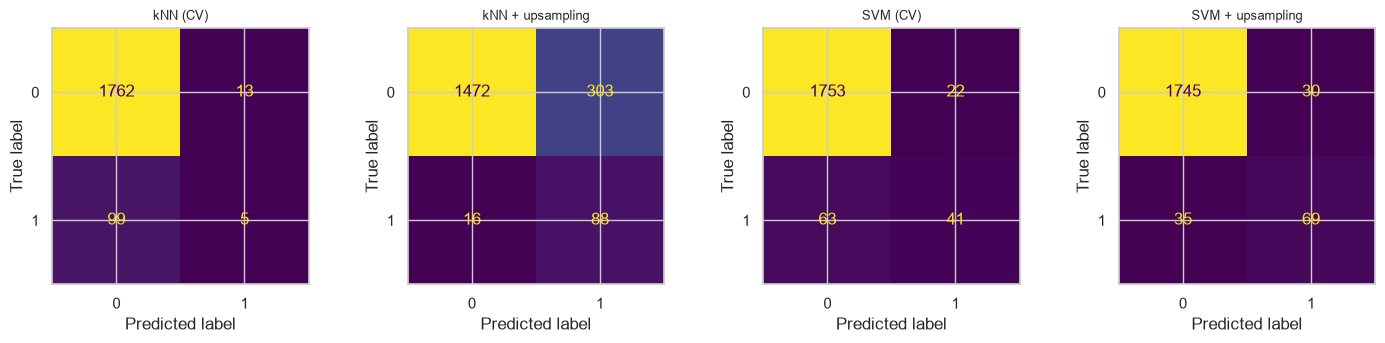

In [17]:
plot_cm(["kNN (CV)", "kNN + upsampling", "SVM (CV)", "SVM + upsampling"])

Upsampling помог обеим моделям, но по-разному. SVM: F1 вырос с 0.491 до 0.680, найдено 69 мошенников вместо 41, ложных тревог стало 30 вместо 22. kNN: найдено 88 мошенников вместо 5, но ложных тревог 303 вместо 13, F1 вырос с 0.082 до 0.356. Вокруг каждого мошенника теперь облако синтетических соседей, и kNN начинает подозревать всех клиентов с низким уровнем доверия.

LogLoss у kNN вырос до 2.17. Модель обучалась на выборке, где мошенников 50%, и её вероятности завышены относительно настоящих 5.5%.

## 2.3. Стэкинг

Первый уровень: kNN, SVM, LogReg. Метамодель – логистическая регрессия, которая получает вероятности базовых моделей, рассчитанные внутренней 5-fold кросс-валидацией.

In [18]:
stack = StackingClassifier(estimators, final_estimator=LogisticRegression(max_iter=5000),
                           stack_method="predict_proba", cv=5)
r, pred, proba = cv_eval(stack, X, y)
results["Stacking"] = r; oof["Stacking"] = (pred, proba)
pd.DataFrame(results).T.round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
SVM (CV),0.955,0.491,0.098,0.969,0.062
LogReg (CV),0.978,0.777,0.061,0.990,0.035
Hard Voting,0.961,0.519,NaN,NaN,0.064
Soft Voting,0.960,0.506,0.090,0.979,0.077
AdaBoost,0.981,0.814,0.351,0.994,0.019
kNN + upsampling,0.830,0.356,2.167,0.876,0.031
SVM + upsampling,0.965,0.680,0.129,0.980,0.084
Stacking,0.974,0.729,0.074,0.989,0.053


Стэкинг дал F1 0.729: лучше голосования (0.519) и немного хуже одной LogReg (0.777). Метамодель сама подбирает веса базовых моделей, поэтому слабый kNN мешает меньше, чем при равном голосе. Обойти LogReg стэкинг не смог: kNN и SVM почти не добавляют информации, которой у неё нет.

## 3.1. Бэггинг с собственным правилом разбиения

Правило: делю **честные** чеки на 10 непересекающихся частей случайным образом. Каждая часть (около 140 чеков в фолде) объединяется со **всеми** мошенниками обучающей выборки. На каждой из 10 подвыборок учу отдельное дерево CART, итоговая вероятность – среднее по деревьям.

Так каждое дерево учится на почти сбалансированных данных (примерно 1 : 1.7), но вместе деревья видят все честные чеки, ничего не выброшено. Для сравнения запускаю обычный бэггинг sklearn с бутстрепом.

In [19]:
from sklearn.base import BaseEstimator, ClassifierMixin

class PartitionBagging(BaseEstimator, ClassifierMixin):
    def __init__(self, base=None, n_parts=10, random_state=RS):
        self.base = base
        self.n_parts = n_parts
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        maj = rng.permutation(np.where(y == 0)[0])
        mino = np.where(y == 1)[0]
        self.models_ = []
        for part in np.array_split(maj, self.n_parts):
            idx = np.concatenate([part, mino])
            self.models_.append(clone(self.base).fit(X[idx], y[idx]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = np.mean([m.predict_proba(np.asarray(X, dtype=float))[:, 1] for m in self.models_], axis=0)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

pbag = PartitionBagging(DecisionTreeClassifier(max_depth=5, random_state=RS), n_parts=10)
r, pred, proba = cv_eval(pbag, X, y)
results["Bagging (разбиение)"] = r; oof["Bagging (разбиение)"] = (pred, proba)

bag = BaggingClassifier(DecisionTreeClassifier(max_depth=5, random_state=RS), n_estimators=50, random_state=RS)
r, pred, proba = cv_eval(bag, X, y)
results["Bagging (бутстреп)"] = r; oof["Bagging (бутстреп)"] = (pred, proba)

pd.DataFrame(results).T.loc[["Bagging (разбиение)", "Bagging (бутстреп)", "AdaBoost"]].round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
Bagging (разбиение),0.930,0.602,0.184,0.973,0.019
Bagging (бутстреп),0.972,0.711,0.079,0.980,0.046
AdaBoost,0.981,0.814,0.351,0.994,0.019


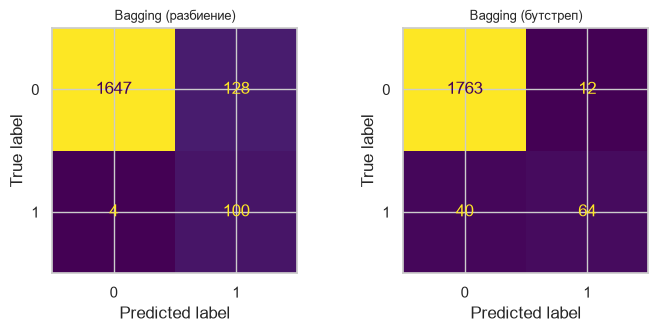

In [20]:
plot_cm(["Bagging (разбиение)", "Bagging (бутстреп)"])

Бэггинг по разбиению нашёл 100 мошенников из 104, больше любой другой модели, но дал 128 ложных тревог, и F1 вышел 0.602. В каждой подвыборке мошенников около 37% вместо 5.5%, поэтому деревья слишком охотно ставят класс 1. Обычный бутстреп сохраняет исходную пропорцию: 64 найденных, 12 ложных тревог, F1 0.711.

Выбор между ними зависит от цены ошибки. Если пропущенная кража стоит дороже проверки честного покупателя, бэггинг по разбиению полезнее, несмотря на худший F1.

## 3.2. Пять моделей: добавляю Naive Bayes и CART, затем LDA

Сначала смотрю каждую новую модель отдельно, потом собираю голосование из пяти: kNN, SVM, LogReg, LDA, CART.

In [21]:
extra = {
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "CART": DecisionTreeClassifier(max_depth=5, random_state=RS),
    "LDA": LinearDiscriminantAnalysis(),
}
for name, m in extra.items():
    r, pred, proba = cv_eval(m, X, y)
    results[name] = r; oof[name] = (pred, proba)

five = estimators + [("LDA", extra["LDA"]), ("CART", extra["CART"])]
for v in ["hard", "soft"]:
    vc = VotingClassifier(five, voting=v)
    r, pred, proba = cv_eval(vc, X, y, has_proba=(v == "soft"))
    results[f"{v.capitalize()} Voting (5 моделей)"] = r
    oof[f"{v.capitalize()} Voting (5 моделей)"] = (pred, proba)

stack5 = StackingClassifier(five, final_estimator=LogisticRegression(max_iter=5000),
                            stack_method="predict_proba", cv=5)
r, pred, proba = cv_eval(stack5, X, y)
results["Stacking (5 моделей)"] = r; oof["Stacking (5 моделей)"] = (pred, proba)

pd.DataFrame(results).T.round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std
kNN (CV),0.940,0.082,0.510,0.828,0.092
SVM (CV),0.955,0.491,0.098,0.969,0.062
LogReg (CV),0.978,0.777,0.061,0.990,0.035
Hard Voting,0.961,0.519,NaN,NaN,0.064
Soft Voting,0.960,0.506,0.090,0.979,0.077
AdaBoost,0.981,0.814,0.351,0.994,0.019
kNN + upsampling,0.830,0.356,2.167,0.876,0.031
SVM + upsampling,0.965,0.680,0.129,0.980,0.084
Stacking,0.974,0.729,0.074,0.989,0.053
Bagging (разбиение),0.930,0.602,0.184,0.973,0.019


Naive Bayes в голосование не беру: он предполагает независимость признаков, а `scannedLineItemsPerSecond` и `valuePerSecond` – производные от времени сканирования и суммы чека. В одиночку он подозревает почти всех: 99 найденных мошенников и 300 ложных тревог.

LDA ранжирует чеки неплохо (ROC-AUC 0.950), но при пороге 0.5 нашла только 3 мошенников. LDA учитывает априорную долю класса 5.5% и поэтому почти никогда не оценивает вероятность мошенничества выше 50%. CART в одиночку даёт F1 0.550.

Голосование из пяти моделей хуже голосования из трёх (F1 0.406 и 0.365 против 0.519 и 0.506): LDA и CART добавили ещё два голоса «честно». Стэкинг из пяти моделей чуть лучше стэкинга из трёх: 0.756 против 0.729, метамодель занизила вес слабых моделей.

## 3.4. Итоговое сравнение

In [22]:
final = pd.DataFrame(results).T
# сколько мошенников найдено (TP), пропущено (FN) и сколько ложных тревог (FP)
for k in final.index:
    tn, fp, fn, tp = confusion_matrix(y, oof[k][0]).ravel()
    final.loc[k, ["TP", "FN", "FP"]] = tp, fn, fp
final = final.sort_values("F1", ascending=False)
final.round(3)

,Accuracy,F1,LogLoss,ROC-AUC,F1 std,TP,FN,FP
AdaBoost,0.981,0.814,0.351,0.994,0.019,79.0,25.0,11.0
LogReg (CV),0.978,0.777,0.061,0.990,0.035,73.0,31.0,11.0
Stacking (5 моделей),0.975,0.756,0.072,0.988,0.057,73.0,31.0,16.0
Stacking,0.974,0.729,0.074,0.989,0.053,66.0,38.0,11.0
Bagging (бутстреп),0.972,0.711,0.079,0.980,0.046,64.0,40.0,12.0
SVM + upsampling,0.965,0.680,0.129,0.980,0.084,69.0,35.0,30.0
Bagging (разбиение),0.930,0.602,0.184,0.973,0.019,100.0,4.0,128.0
CART,0.949,0.550,0.549,0.891,0.081,58.0,46.0,49.0
Hard Voting,0.961,0.519,NaN,NaN,0.064,40.0,64.0,10.0
Soft Voting,0.960,0.506,0.090,0.979,0.077,39.0,65.0,11.0


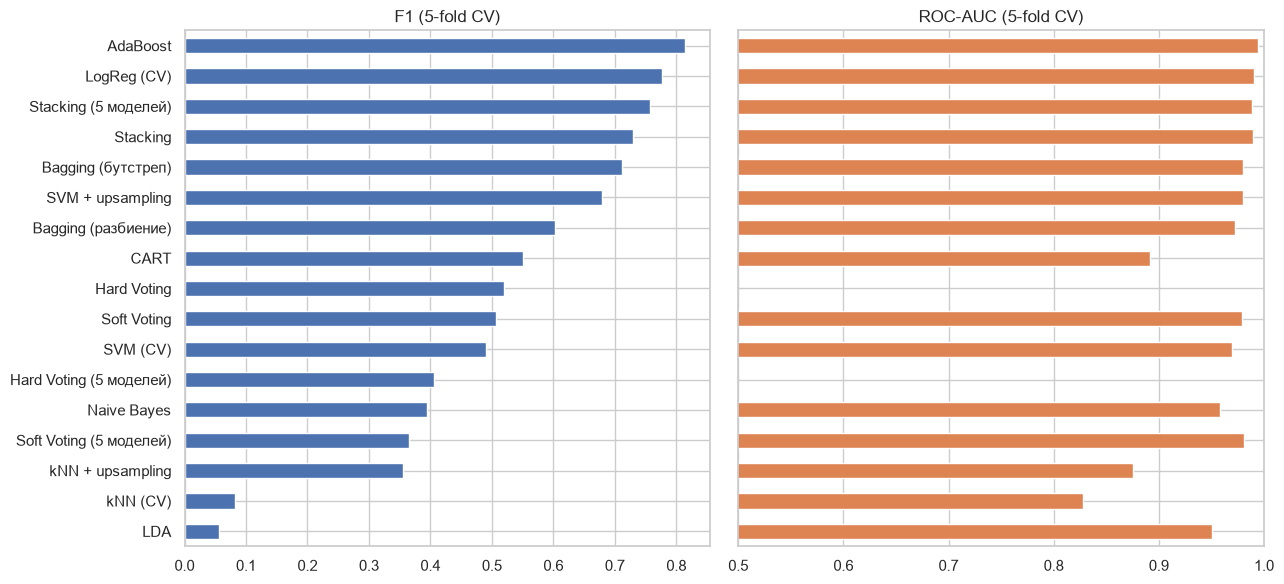

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
order = final.index
final.loc[order, "F1"].plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("F1 (5-fold CV)")
final.loc[order, "ROC-AUC"].plot.barh(ax=axes[1], color="#DD8452"); axes[1].set_title("ROC-AUC (5-fold CV)")
axes[1].set_xlim(0.5, 1)
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

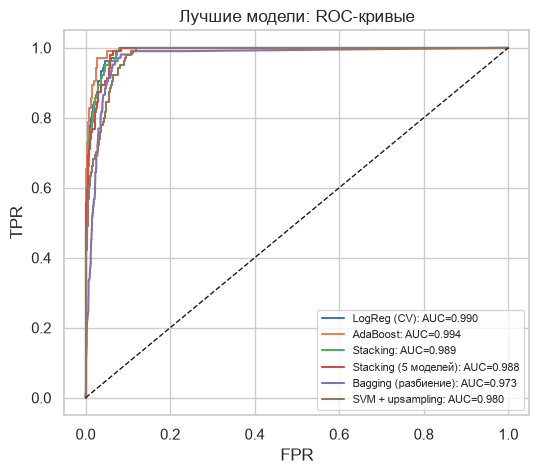

In [24]:
plot_roc(["LogReg (CV)", "AdaBoost", "Stacking", "Stacking (5 моделей)", "Bagging (разбиение)", "SVM + upsampling"],
         "Лучшие модели: ROC-кривые")

#### Выводы

1. Лучшая модель по F1 и ROC-AUC – AdaBoost над деревьями глубины 2: F1 0.814, ROC-AUC 0.994, 79 найденных мошенников из 104 при 11 ложных тревогах. Лучшие вероятности (LogLoss 0.061) у логистической регрессии, по F1 она уступает AdaBoost на 0.04.
2. 5-fold кросс-валидация подтвердила порядок моделей из прошлой работы и уточнила оценки на 0.02–0.07: в тесте отложенной выборки был всего 31 мошеннический чек.
3. Голосование здесь вредит: kNN и SVM слабее LogReg и ошибаются одинаково. Стэкинг сам подбирает веса и лучше переносит слабые модели, но LogReg тоже не обходит.
4. Upsampling полезен SVM (F1 с 0.491 до 0.680). kNN после него стал подозревать всех клиентов с низким trustLevel.
5. Бэггинг по разбиению честных чеков на 10 частей находит 100 мошенников из 104. Если ложная тревога дешевле пропущенной кражи, это лучший вариант, хотя по F1 он проигрывает из-за 128 ложных тревог.
6. Accuracy в этой задаче почти ничего не говорит: у LDA она 0.946 при трёх найденных мошенниках.